## Objetivo 4 Realizar un modelo predictivo de la variable impago

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from sklearn.metrics import make_scorer, fbeta_score, classification_report
import warnings


In [2]:
warnings.filterwarnings("ignore")

## Analisis del CSV y selección justificada de las metricas de evaluacion para el modelo

In [3]:
df = pd.read_csv("Data/df_filtrado.csv")

In [4]:
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Fiador,Impago,Prima,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,0.0,0,65.85,0,1,0,0,0,0,1
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,0.0,0,260.60,0,0,1,0,1,0,0
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,1.0,0,221.02,0,0,1,0,1,0,0
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,0.0,0,125.00,0,0,1,0,1,0,0
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,0.0,0,800.00,0,0,1,0,0,0,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101886 entries, 0 to 101885
Data columns (total 23 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   ID                                     101886 non-null  str    
 1   Edad                                   101886 non-null  int64  
 2   Ingresos                               101886 non-null  float64
 3   Monto_Inicial                          101886 non-null  int64  
 4   Scoring_Crediticio                     101886 non-null  int64  
 5   Meses_Empleo                           101886 non-null  float64
 6   Num_Creditos                           101886 non-null  int64  
 7   Ratio_Interes                          101886 non-null  float64
 8   Duracion                               101886 non-null  float64
 9   Ratio_Deuda_Ingresos                   101886 non-null  float64
 10  Estudios                               101886 non-null  int64  
 11

Lo siguiente va a ser ver la correlacion entre las variables , ya que si hay una correlacion alta entre estas fallariamos uno de los supuestos para la regresion logistica y por lo tanto nuestro modelo tendria multicolinealidad

In [6]:
df = df.drop(columns="ID")

In [7]:
corr = df.corr().abs().stack()
corr[(corr > 0.7) & (corr < 1)]

Edad          Meses_Empleo    0.941027
Meses_Empleo  Edad            0.941027
dtype: float64

Lo que se ha hecho en la celda anterior ha sido crear una matriz de correlacion, al haber tantas variables hemos optado por pasar esa matriz a una lista. Además he pasado la correlacion a valor absoluto porque puede aver tanto correlacion postiva como correlacion negativa. Finalmente, hemos pedido que nos devuelva solo las variables en las que su correlacion es mayor a 0,70. El resultado ha sido que la variable meses_empleo y edad tienen una fuerte correlacion positiva (0.94).

Como tenemos que seleccionar una y ambas son bastante parecidas voy a optar con quedarme con Edad porque es una variable más sencilla de explicar

In [8]:
df = df.drop(columns="Meses_Empleo")

Como este dataset ya ha sido filtrado, ni tenemos nulos ni variables categoricas, por lo que podemos seguir viendo la viariable impago.

Aun asi viendo las variables me he dado cuenta que a la hora de hacer un get dummies de las variables categoricas se nos olvido eliminar una columna por lo que vamos a eliminar una de cada una. Esto es necesario porque de no hacerlo la suma de las categorias siempre sera 1 porque imaginate si tengo tres categorias (en formato dummy) y se dos de ellas no necesito la tercera 

Para ello he decidido eliminar la mas frecuente en ambas para que sea una referencia intuitiva

Primero vamos a elegir las columnas de cada categoria

In [9]:
cols_estado_civil = ["Estado_Civil_Casado", "Estado_Civil_Divorciado", "Estado_Civil_Soltero"]
cols_jornada = ["Tipo_Jornada_Laboral_Autónomo", "Tipo_Jornada_Laboral_Desempleado",
                "Tipo_Jornada_Laboral_Jornada completa", "Tipo_Jornada_Laboral_Tiempo parcial"]

In [10]:
estado_civil_media = df[cols_estado_civil].mean()
print(estado_civil_media)

Estado_Civil_Casado        0.511778
Estado_Civil_Divorciado    0.186424
Estado_Civil_Soltero       0.301798
dtype: float64


In [11]:
df= df.drop(columns="Estado_Civil_Casado")

In [12]:
jornada_media = df[cols_jornada].mean()
print(jornada_media)

Tipo_Jornada_Laboral_Autónomo            0.148519
Tipo_Jornada_Laboral_Desempleado         0.099513
Tipo_Jornada_Laboral_Jornada completa    0.550056
Tipo_Jornada_Laboral_Tiempo parcial      0.201912
dtype: float64


In [13]:
df= df.drop(columns="Tipo_Jornada_Laboral_Jornada completa")

Ahora vamos a eliminar la viariable prima ya que esta varia depiendiendo de la probabilidad de impago y como no sabemos cual es la probabilidad de impago de momento vamos a eliminar esta variable

In [14]:
df = df.drop(columns="Prima")

Ahora procedemos a analizar la variable objetivo

In [15]:
df["Impago"].value_counts()

Impago
0    90158
1    11728
Name: count, dtype: int64

In [16]:
df["Impago"].value_counts(normalize=True) * 100

Impago
0    88.489096
1    11.510904
Name: proportion, dtype: float64

La variable impago esta desbalanceada claramente esto nos ayuda a definir la metricas de evaluacion. En el 88.48 % de los casos el prestamo se paga, por lo que el modelo sin aprender nada simplemente diciendo que todas se pagan tendria un 88.49 % de acuraccy (de todos los datos cuantos he acertado). Esto nos dice que la metrica de evaluacion acuraccy puede llegar a ser engañosa. Por ello, vamos a usar esta metrica solo para compararla con este 88.48% que tendria si el modelo no aprendiese.

Por otro lado, Para la clasificacion vamos a centrarnos en las metricas Precision y Recall:

Recall: de los todos los positivos, cuatos detectas.

Precision: de los que detectas como positivos cuantos lo son de verdad.

Ademas vamos a dar mas importancia al Recall porque consideramos que el coste de no detectar un impago es mas alto para la aseguradora, que el de marcar a una persona marcada como posible no pagador y que luego finalmente termine pagando. Aun asi hay que tener en cuenta que estas metricas solo van a ayudarnos a elegir un umbral para la posterior clasificacion

Por otro lado, como nuestro objetivo principal es calcular la probabilidad de impago para meterla en en el modelo de la prediccion de prima vamos a centrarnos en el area bajo la curva. 

Area Bajo la Curva (Roc / Auc) : La curva traza la tasa de verdaderos positivos (sensibilidad) frente a la tasa de falsos positivos (FPR) (proporción de instancias negativas que se clasifican de manera incorrecta como positivas). 

Nos centramos en el area bajo la curva para asegurarnos que neustras probabilidades ordenan mejor que el azar (50%)







## Separar los datos en tres conjuntos (TRAIN, TEST y PUBLICO)

A continuacion vamos a separar los datos en tres conjunto Train, Test y Publico. Con Train vamos a entrenar el modelo. Con test vamos a validar ese modelo. Por ultimo con publico (que va a ser una muestra sacada del df desde el principio y no se va a tocar en ningun momento), vamos a simular el rendimiento de nuestro modelo cuando salga al los datos publicos

In [17]:
df_modelo = df.copy()

#cogemos el 10% de los datos de nuestro df 
df_publico = df_modelo.sample(frac=0.10, random_state=42) #la funcion sample nos permite coger filas al azar ademas con random_state 42 creamos una semilla para que siempre coja las mismas filas que se seleccionaron la primera vez de su ejecucion

df_modelo = df_modelo.drop(df_publico.index) #ahora vamos a quitar del df modelo las filas que hemos seleccionado con el sample 

In [18]:
df_publico["Impago"].value_counts(normalize= True)*100

Impago
0    88.850721
1    11.149279
Name: proportion, dtype: float64

Vemos que en el conjunto publico se mantiene el desbalance que existe en la variable impago, un 11,14 % de impagos, por lo que podemos seguir separando en train test

Vamos a separar ahora si en train y test con la variable stratify para que los datos de la variable impago mantengan el desbalance, además añadimos la funcion shuffle para asegurarnos la aleatoriedad de la muestra


In [19]:
y = df_modelo["Impago"]
X = df_modelo.drop(columns="Impago")

In [20]:
X_publico = df_publico.drop(columns=["Impago"])
y_publico = df_publico["Impago"]

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=df_modelo["Impago"], shuffle=True, random_state=42, train_size= 0.8)

Ahora vamos a ver los valores de x_train

In [22]:
X_train.describe()

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Posesion_Hipoteca,Personas_Cargo,Fiador,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Divorciado,Estado_Civil_Soltero
count,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000,73357.00000,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000,73357.000000
mean,39.645119,41465.166037,45050.881838,692.273471,1.995924,10.678138,37.27677,0.321583,0.927014,0.352441,0.449010,0.297150,0.146803,0.098995,0.202053,0.186499,0.301375
std,10.107522,16027.314384,46681.109694,87.297816,0.995846,3.796769,14.18228,0.181365,0.927105,0.477734,0.497397,0.457006,0.353911,0.298658,0.401534,0.389511,0.458859
min,19.000000,16000.000000,3000.000000,398.000000,1.000000,2.010000,12.00000,0.100000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,33.000000,30437.000000,14978.000000,636.000000,1.000000,7.970000,24.00000,0.140000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,39.000000,39059.000000,40000.000000,704.000000,2.000000,10.600000,36.00000,0.290000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,46.000000,50123.000000,47534.000000,760.000000,3.000000,13.260000,48.00000,0.550000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,64.000000,120000.000000,400000.000000,845.000000,4.000000,24.440000,60.00000,0.550000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Entrenamos el modelo

Antes de entrenar el modelo vamos a escalar las variables para que el algoritmo no de mas valor a las variables con datos mas altos, además asi nos aseguramos que no haya problemas de escala. Aun asi no vamos a escalar todas las variables ya que he considerado no escalar las dummy para que se mantenga como esta

In [23]:
columnas_a_escalar = ["Edad", "Ingresos", "Monto_Inicial", "Scoring_Crediticio",
                      "Num_Creditos", "Ratio_Interes", "Duracion", "Ratio_Deuda_Ingresos"]

scaler = StandardScaler()

X_train_scal = X_train.copy()
X_test_scal = X_test.copy()
X_publico_scal = X_publico.copy()

X_train_scal[columnas_a_escalar] = scaler.fit_transform(X_train[columnas_a_escalar])
X_test_scal[columnas_a_escalar] = scaler.transform(X_test[columnas_a_escalar])
X_publico_scal[columnas_a_escalar] = scaler.transform(X_publico[columnas_a_escalar])

Una vez escalado vamos a entrenar el modelo con statsmodel. Elijo statsmodel porque me deja ver los intervalos de confianza para el cliente y ademas puede ver si las correlaciones son significativas y en el caso de que no lo sean puedo eliminarlas y asi respetar la parsimonia 

In [24]:
X_train_scal = sm.add_constant(X_train_scal, prepend=True)
modelo_log_statsm = sm.Logit(endog= y_train, exog = X_train_scal)
modelo_log_statsm = modelo_log_statsm.fit()
print(modelo_log_statsm.summary())

Optimization terminated successfully.
         Current function value: 0.334303
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:                73357
Model:                          Logit   Df Residuals:                    73339
Method:                           MLE   Df Model:                           17
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                 0.06593
Time:                        13:47:44   Log-Likelihood:                -24523.
converged:                       True   LL-Null:                       -26254.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
const                                  -2.2980      0.033 

para entender los resultados de este modelo vamos a explicar conceptos clave

**verosimilitud** : Es la probabilidad que le ha dado nuestro modelo a lo que realmente ha ocurrido, en el summary la vamos a ver como el log likelihood ya que el numero de la verosimilitud de un modelo es tan pequeño que seria muy dificil de manejar.

**Pseudo R2** : Es cuanto mejora la verosimilitud de nuestro modelo frente al de un modelo nulo que predice con la media

El pseudo R² es bajo porque el impago depende de factores que no están en los datos (cualquier imprevisto), por lo que en los modelos de impago se asignan probabilidades moderadas lo que hacen que la verosimimilitud de nuestro modelo no mejore aunque acierte. Es por esto que vamos a evaluar nuestro modelo con metricas como el AUC y el Recall

Para optimizar el modelo vamos a quitar todas las variables con un P-Valor mayor que 0,05 con esto aceptamos la hipotesis nula y decimos que la correlacion en esos casos no es significativa

In [25]:
variables_quitar = [
    "Ingresos",
    "Ratio_Deuda_Ingresos",
    "Posesion_Hipoteca",
    "Personas_Cargo",
    "Fiador",
    "Num_Creditos",
    "Tipo_Jornada_Laboral_Autónomo",
    "Tipo_Jornada_Laboral_Desempleado",
    "Tipo_Jornada_Laboral_Tiempo parcial",
    "Estado_Civil_Divorciado",
    "Estado_Civil_Soltero",
]

In [26]:
X_train_hipotesisnula =X_train_scal.drop(columns=variables_quitar)
X_test_hipotesisnula = X_test_scal.drop(columns=variables_quitar)

In [27]:
X_train_hipotesisnula.drop(columns="const")

,Edad,Monto_Inicial,Scoring_Crediticio,Ratio_Interes,Duracion,Estudios
10860,-1.053195,-0.182171,-0.243690,-0.660603,-1.782290,2
18989,-0.558511,-0.266745,1.245475,-0.041651,1.602238,1
9036,0.925543,0.067868,0.649809,-0.481502,-1.782290,0
46781,1.321290,-0.567640,0.890367,-0.858140,-0.090026,0
91867,-1.152132,-0.598338,-0.197870,1.293704,-0.090026,1
...,...,...,...,...,...,...
36835,1.717038,-0.120839,-0.048953,-1.253216,1.602238,1
97806,-0.954258,-0.355240,-1.194465,1.164646,1.602238,0
9507,-2.042564,-0.108200,0.833091,0.377129,0.756106,0
81569,-0.360637,-0.108200,1.508943,0.859121,0.756106,0


In [28]:
X_train_hipotesisnula = sm.add_constant(X_train_hipotesisnula, prepend=True)
modelo_log_statsm = sm.Logit(endog= y_train, exog = X_train_hipotesisnula)
modelo_log_statsm = modelo_log_statsm.fit()
print(modelo_log_statsm.summary())

Optimization terminated successfully.
         Current function value: 0.334384
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:                73357
Model:                          Logit   Df Residuals:                    73350
Method:                           MLE   Df Model:                            6
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                 0.06570
Time:                        13:47:44   Log-Likelihood:                -24529.
converged:                       True   LL-Null:                       -26254.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -2.2563      0.019   -121.203      0.000      -2.293      -2.220
Edad 

Hemos pasado de un modelo de 17 variables a uno de 6 y comparando ambos modelos nos damos cuenta de que la diferencia es inapreciable, ya que pasamos de tener un log likelihood de -24.523 a -24.529 y el pseudo R² de 0,0659 a 0,0657. por lo que nos quedamos con este modelo ya que es mas simple y los resultados van a ser muy parecidos

## Regularizacion del modelo y Busqueda de hiperparametros

Vamos a regularizar el modelo con Lasso , Ridge y Elasticnet y quedarnos con el mejor resultado tb vamos a compararlo con el error sin regularizar

Regularizamos con L1 (Lasso), lasso es capaz de reducir el coeficiente de las variables menos relevantes a 0 por lo que es un sistema muy util para realizar modelos mas simples

In [29]:
modelo_l1 = LogisticRegressionCV(Cs=np.logspace(-4, 4, 20), cv=5, penalty="l1", solver="saga",
                                 scoring="roc_auc", max_iter=5000, random_state=42)
modelo_l1.fit(X_train_hipotesisnula, y_train)

print("Mejor C:", modelo_l1.C_[0])
print("AUC:", modelo_l1.scores_[1].mean(axis=0).max())

Mejor C: 1.623776739188721
AUC: 0.6894313710525427


Ahora vamos a regularizar con L2 (Ridge): Ridge no reduce ninguna variable a 0 pero si que las penaliza reduciendolas.

In [30]:
modelo_l2 = LogisticRegressionCV(Cs=np.logspace(-4, 4, 20), cv=5, penalty="l2", solver="saga",
                                 scoring="roc_auc", max_iter=5000, random_state=42)
modelo_l2.fit(X_train_hipotesisnula, y_train)

print("Mejor C:", modelo_l2.C_[0])
print("AUC:", modelo_l2.scores_[1].mean(axis=0).max())

Mejor C: 11.288378916846883
AUC: 0.6894308885944553


Ahora vamos a regularizar con elasticnet: elasticnet es una mezcla entre ambos metodos (L1 y L2) por lo que nos da un equilibrio entre ambos metodos. Este metodo tiene un Hiperparametro nuevo llamado L1_ratio, a mayor L1_ratio mas se comporta como lasso el elasticnet

In [31]:
modelo_en = LogisticRegressionCV(Cs=np.logspace(-4, 4, 20), cv=5, penalty="elasticnet", solver="saga", l1_ratios=[0.2, 0.5, 0.8], scoring="roc_auc", max_iter=5000, random_state=42)


modelo_en.fit(X_train_hipotesisnula, y_train)

print("Mejor C:", modelo_en.C_[0])
print("l1_ratio:", modelo_en.l1_ratio_[0])
print("AUC:", modelo_en.scores_[1].mean(axis=0).max())

Mejor C: 0.615848211066026
l1_ratio: 0.5
AUC: 0.6894312710691815


Ahora vamos a ver como se comporta el modelo sin regularizar:

In [32]:
modelo_sin_reg = LogisticRegression(penalty=None, solver="saga", max_iter=5000)
auc_sin_reg = cross_val_score(modelo_sin_reg, X_train_hipotesisnula, y_train, cv=5, scoring="roc_auc").mean()


print("AUC:", auc_sin_reg)

AUC: 0.6894304974684298


Hemos comparado la regresión logistica sin regularizar con las penalizaciones Lasso, Ridge y Elastic Net, eligiendo el hiperparametro C por validación cruzada (5 folds) con el AUC como métrica. Los cuatro modelos alcanzan un AUC parecido (≈0,689), por lo que la regularización no aporta mejora: con 73.000 observaciones y solo 6 variables no hay sobreajuste. Nos quedamos con el modelo sin regularizar por ser el más simple.

## Entrenamiento del modelo con los hiperparametros optimos

In [33]:
X_train_hipotesisnula = X_train_hipotesisnula.drop(columns="const")

In [34]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(penalty=None, solver="saga", max_iter=5000, class_weight="balanced")

modelo.fit(X_train_hipotesisnula, y_train)

y_pred = modelo.predict(X_test_hipotesisnula)




In [35]:
print(y_pred[:10])

[1 1 0 0 0 1 1 1 0 1]


In [36]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.63      0.75     16222
           1       0.19      0.65      0.29      2118

    accuracy                           0.64     18340
   macro avg       0.56      0.64      0.52     18340
weighted avg       0.85      0.64      0.70     18340



<Axes: >

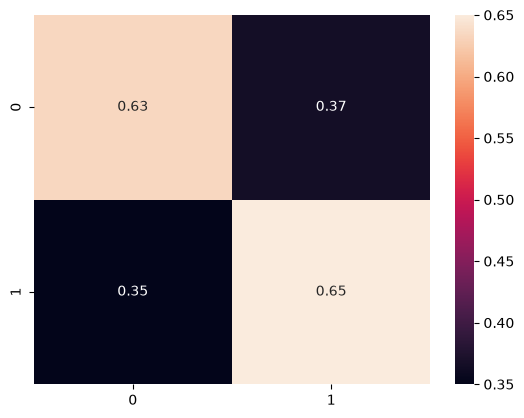

In [37]:
from sklearn.metrics import confusion_matrix

sns.heatmap(confusion_matrix(y_test,y_pred, normalize='true'), annot=True)

In [38]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test, y_pred)

0.641955299399305